# <center> **MATH&ML-9. Математика ансамблевых методов**

Составление прогнозов в машинном обучении может следовать такой же логике: один алгоритм часто даёт далёкий от желаемой точности прогноз, ведь у каждого метода есть свои ограничения, и в целом создание модели, которая строит очень близкие к реальности предсказания, — достаточно сложная задача. Однако если мы обучим на наших данных несколько моделей и обобщим результаты определённым образом, то сможем получить куда более точный результат.

Такой алгоритм решения задач машинного обучения называется **ансамблем моделей**.

>**Ансамбль моделей** — это метод, в котором несколько алгоритмов (или вариации одного и того же) обучаются на одних данных, а итоговый прогноз строится на основе всех полученных от моделей прогнозов.

## <center> 2. Ансамбли моделей. Бутстреппинг. Бэггинг

В основе бэггинга лежит статистический метод, который называется бутстрепом (bootstrap). Идея бутстрепа заключается в генерации выборок размера n из исходного датасета размера N путём случайного выбора элементов с повторениями в каждом из наблюдений.

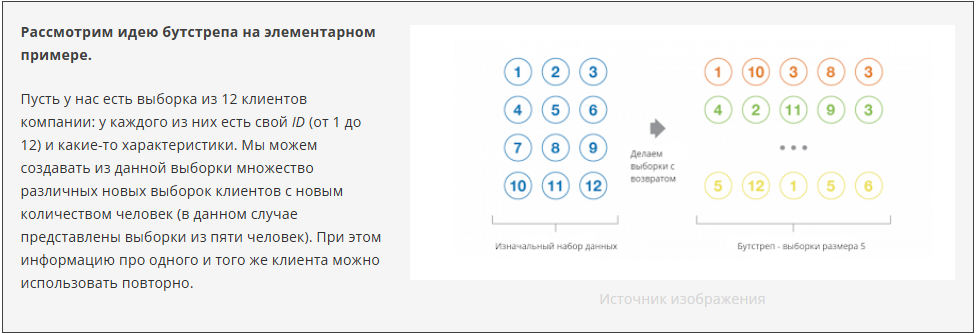

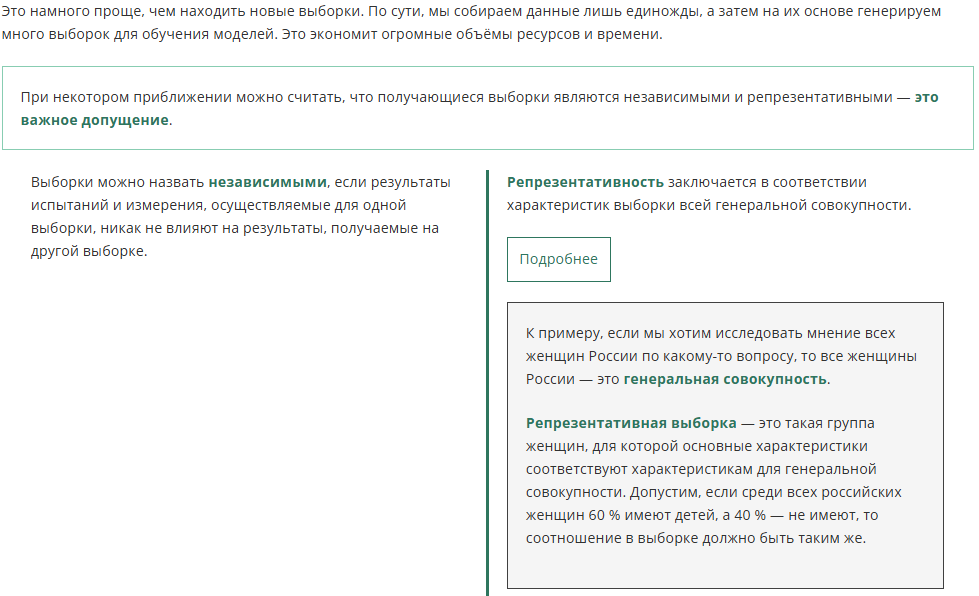

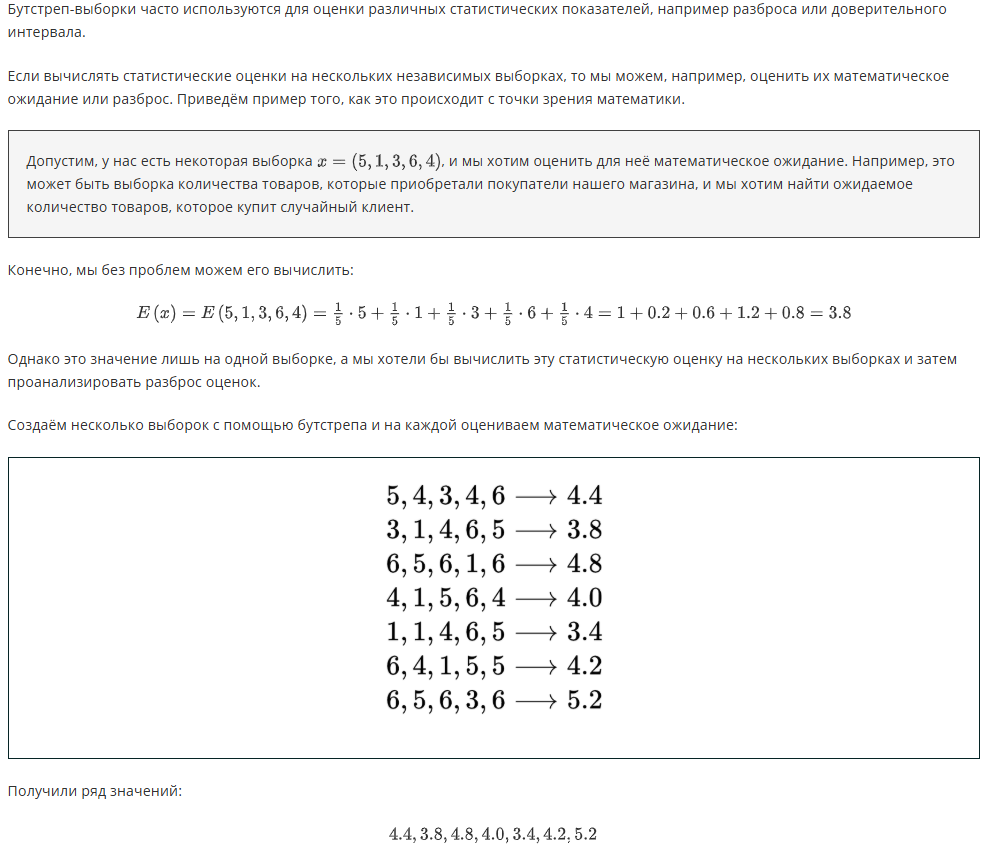

D(x)=0.317

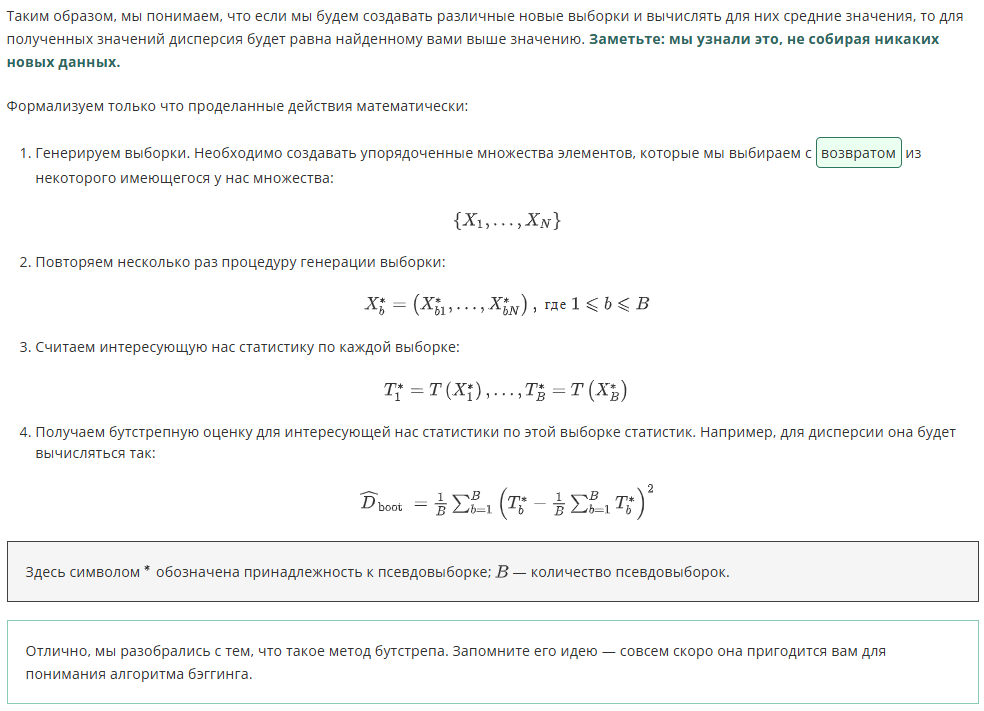

## <center> Bias и Variance

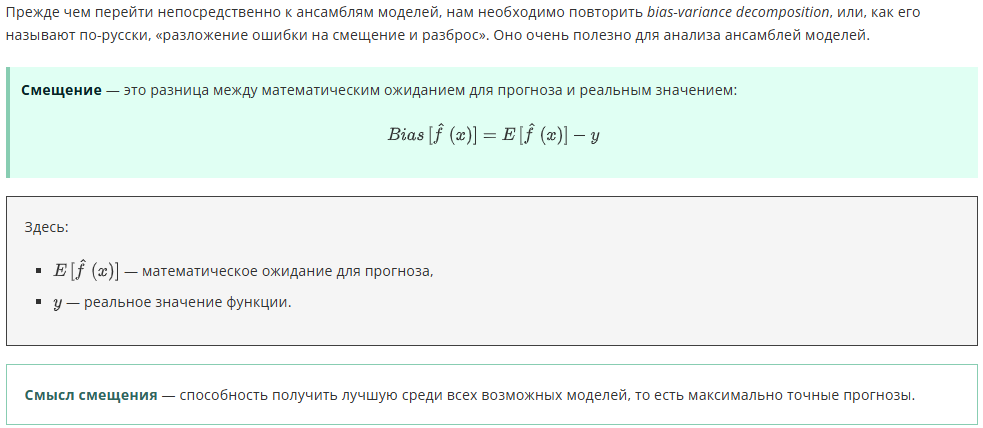

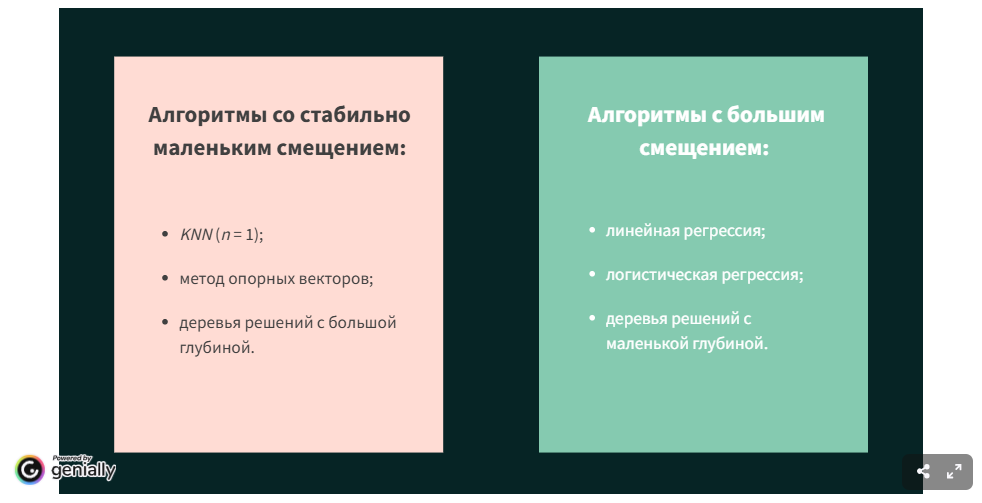

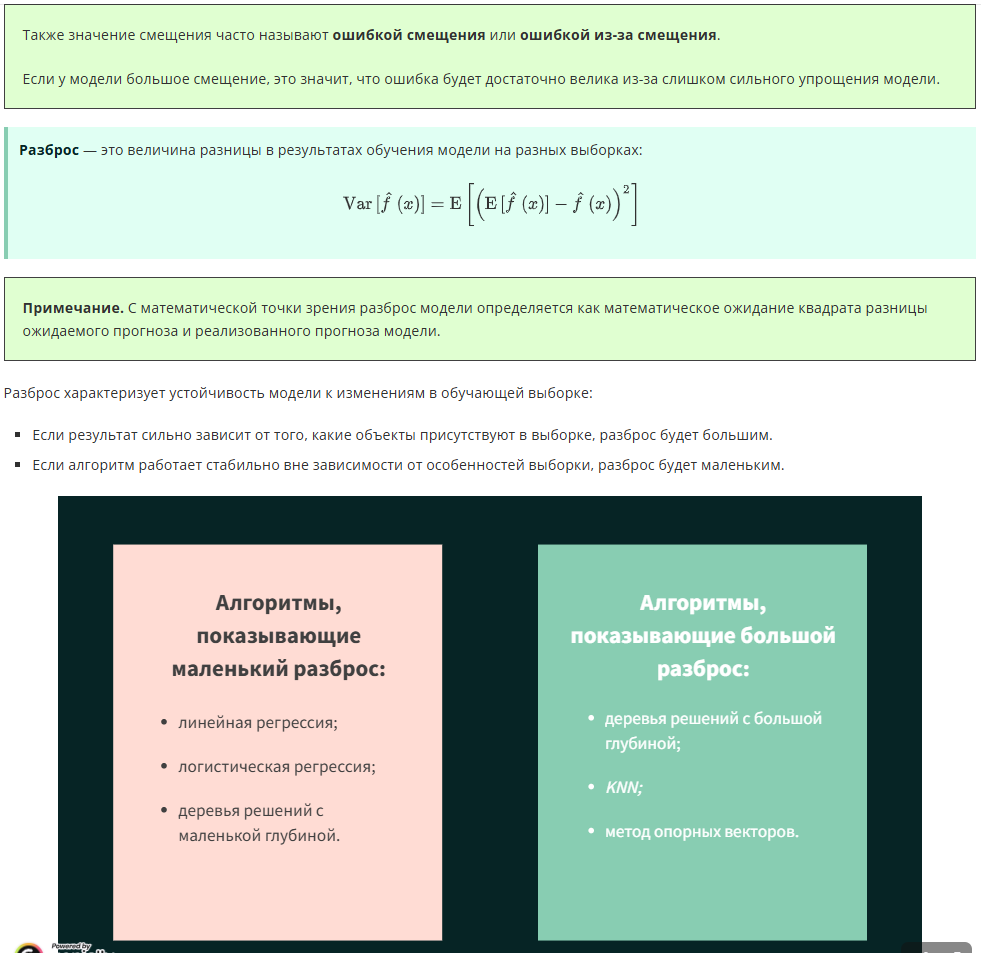

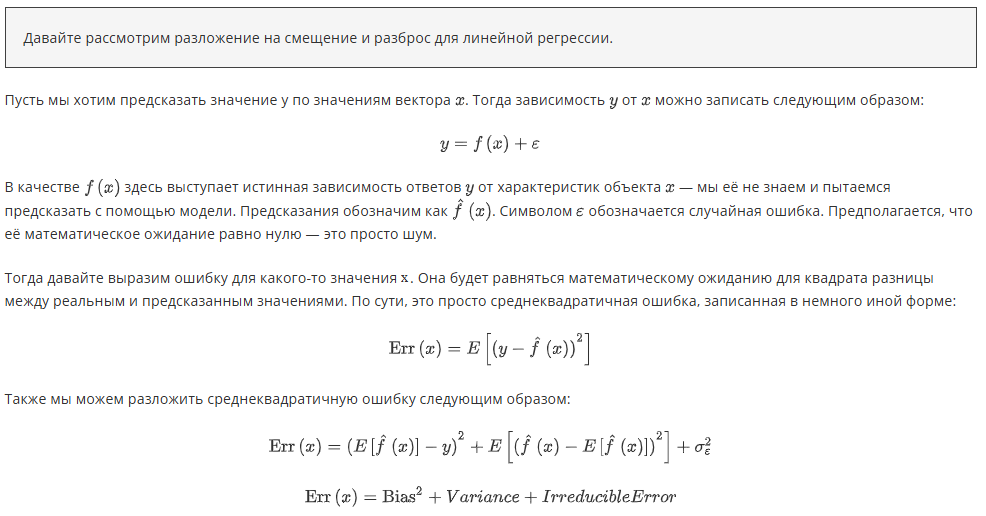

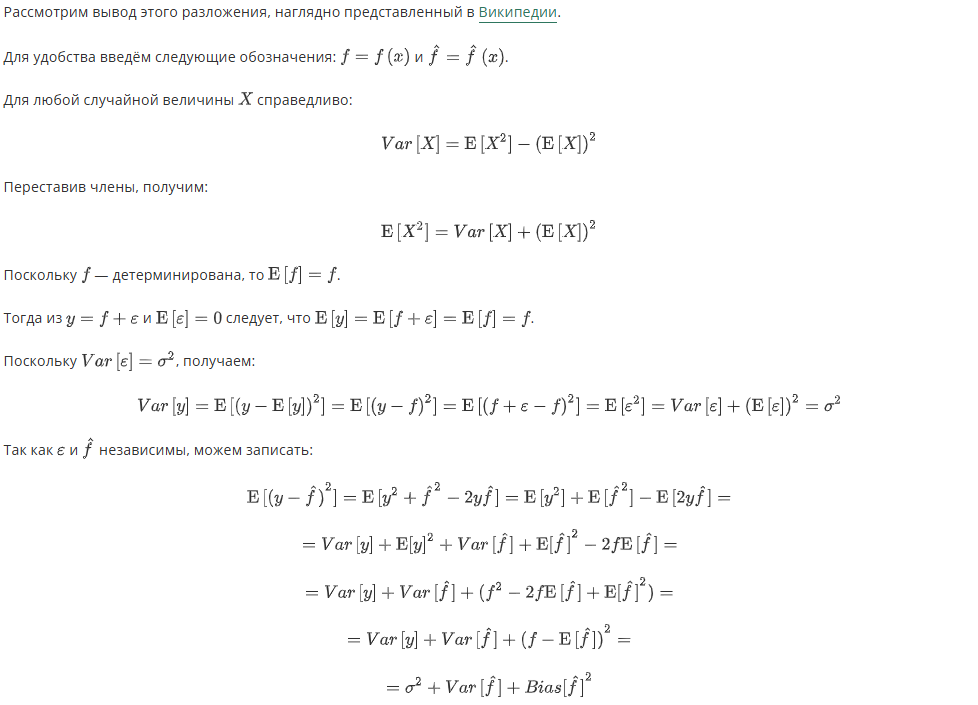

Итак, мы получили, что наша ошибка — это сумма квадрата смещения, разброса и неустранимой случайной ошибки. Теперь мы понимаем, из чего состоит ошибка модели. Такое представление помогает нам исследовать с теоретической точки зрения некоторые алгоритмы машинного обучения и часто используется при изучении ансамблей.

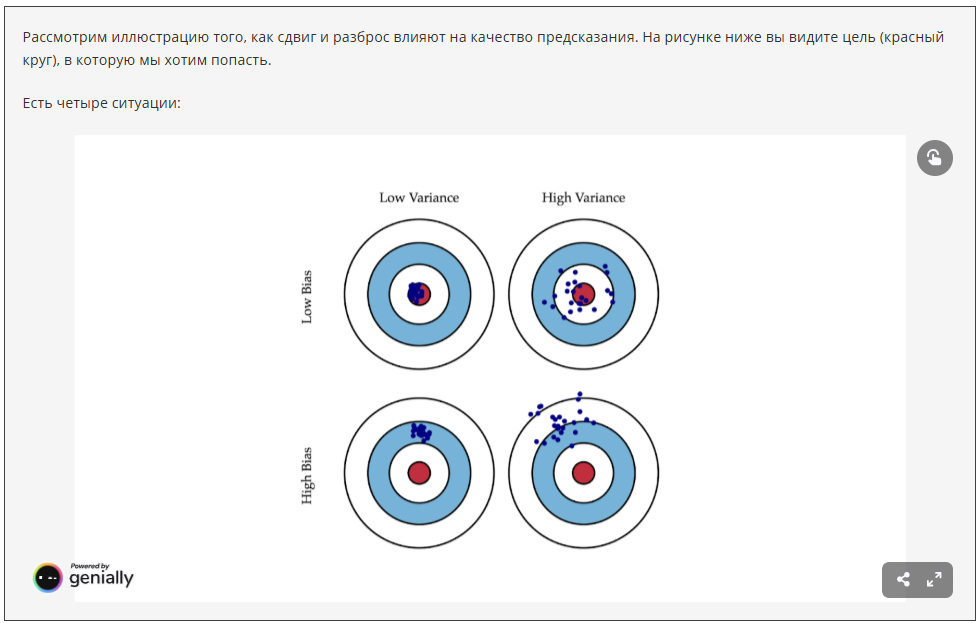

В моделях машинного обучения принцип тот же, только в качестве центра мишени выступает минимально возможная ошибка.

Когда говорят про разложение на *bias* и *variance*, то часто упоминают некую **точку баланса**:
* Если модель очень простая, с маленьким количеством параметров, то, скорее всего, у неё будет **очень большое смещение, но маленький разброс**.
* Если модель очень сложная, со множеством параметров, у неё будет **большой разброс и маленькое смещение**.

Схематично эти зависимости можно изобразить следующим образом (это схема не для конкретной модели, а лишь иллюстрация тенденций):

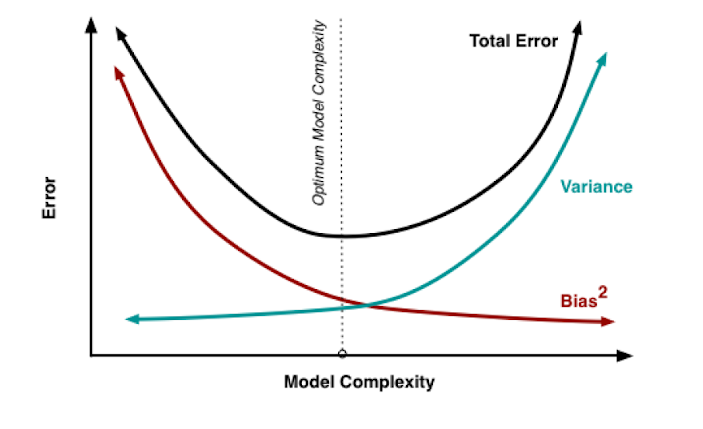

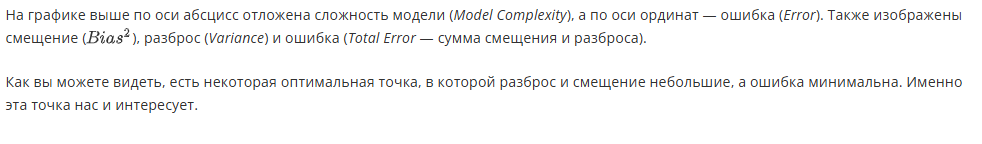

## <center> Бэггинг

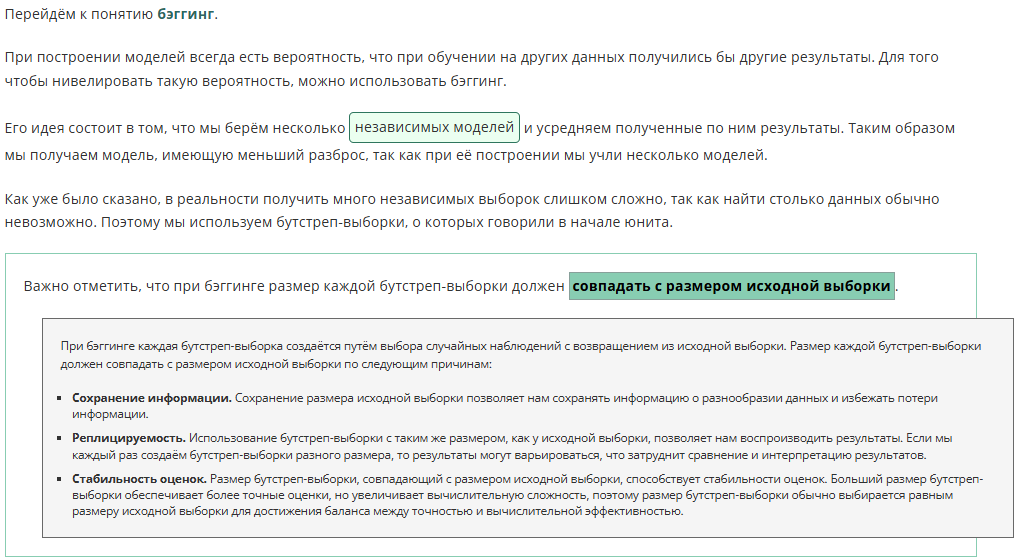

Схематично процесс бэггинга можно представить следующим образом:

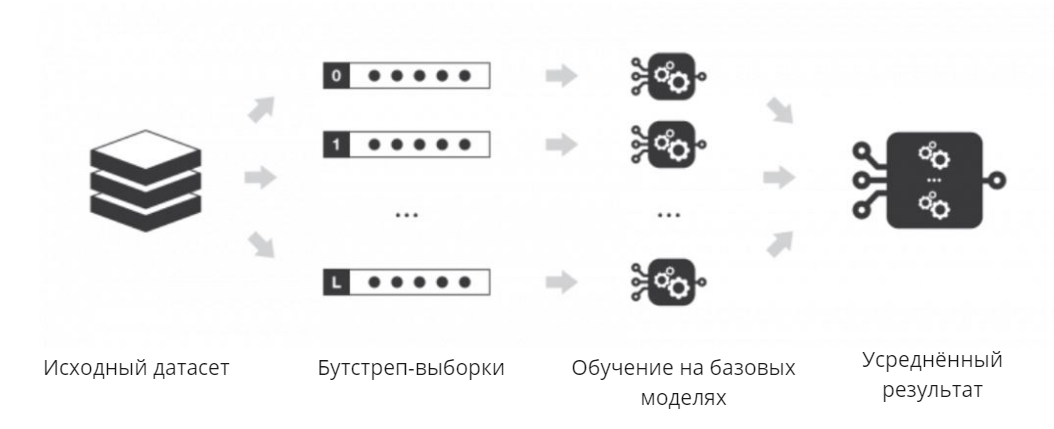

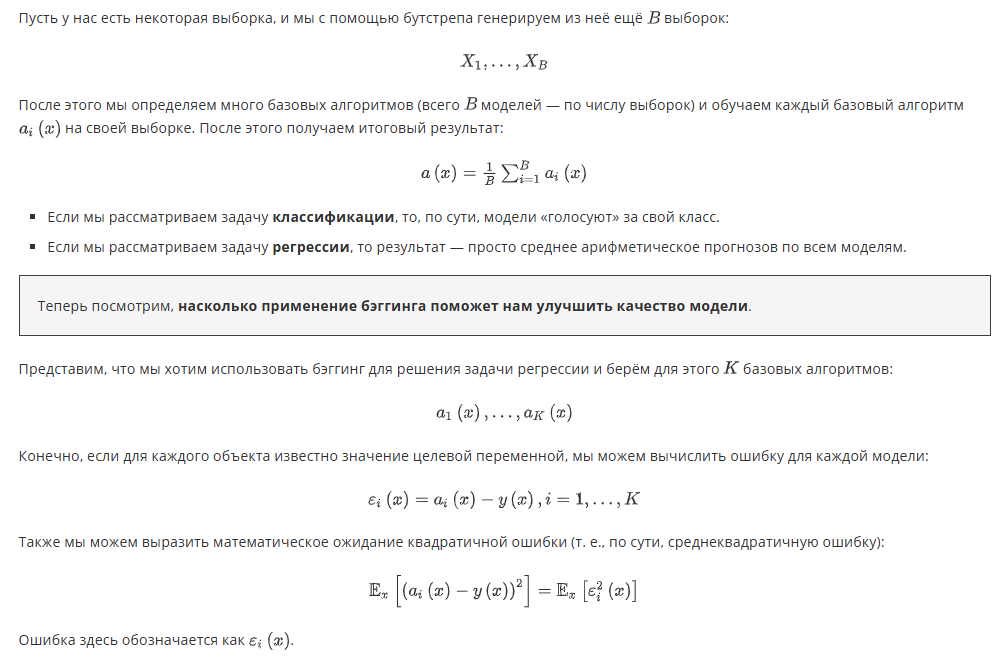

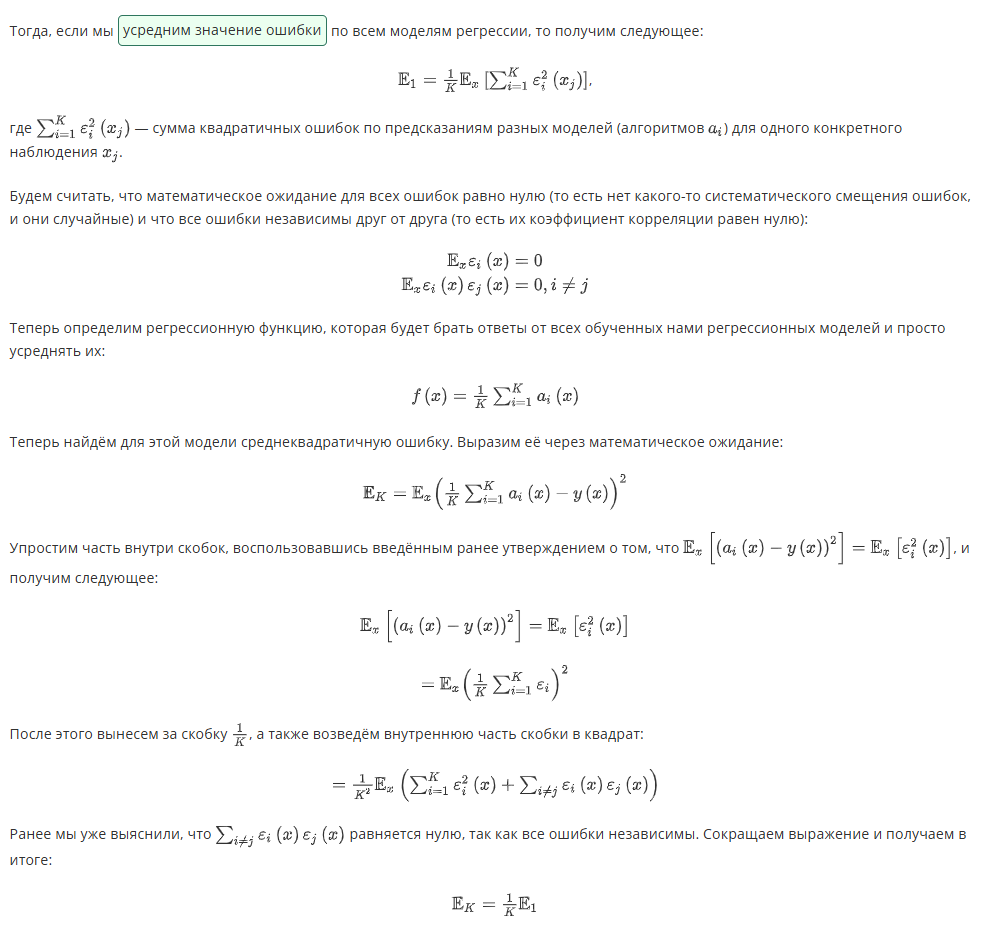

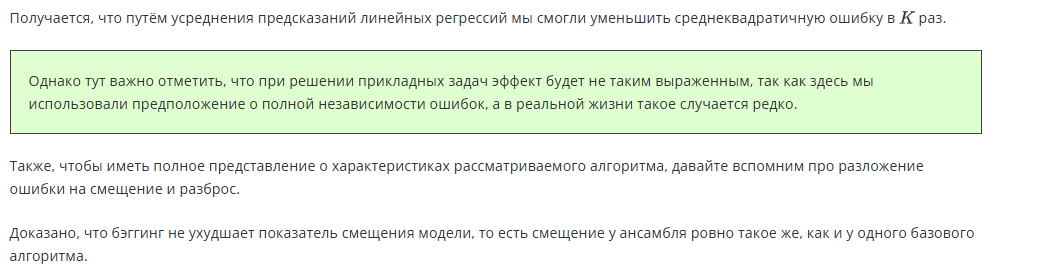

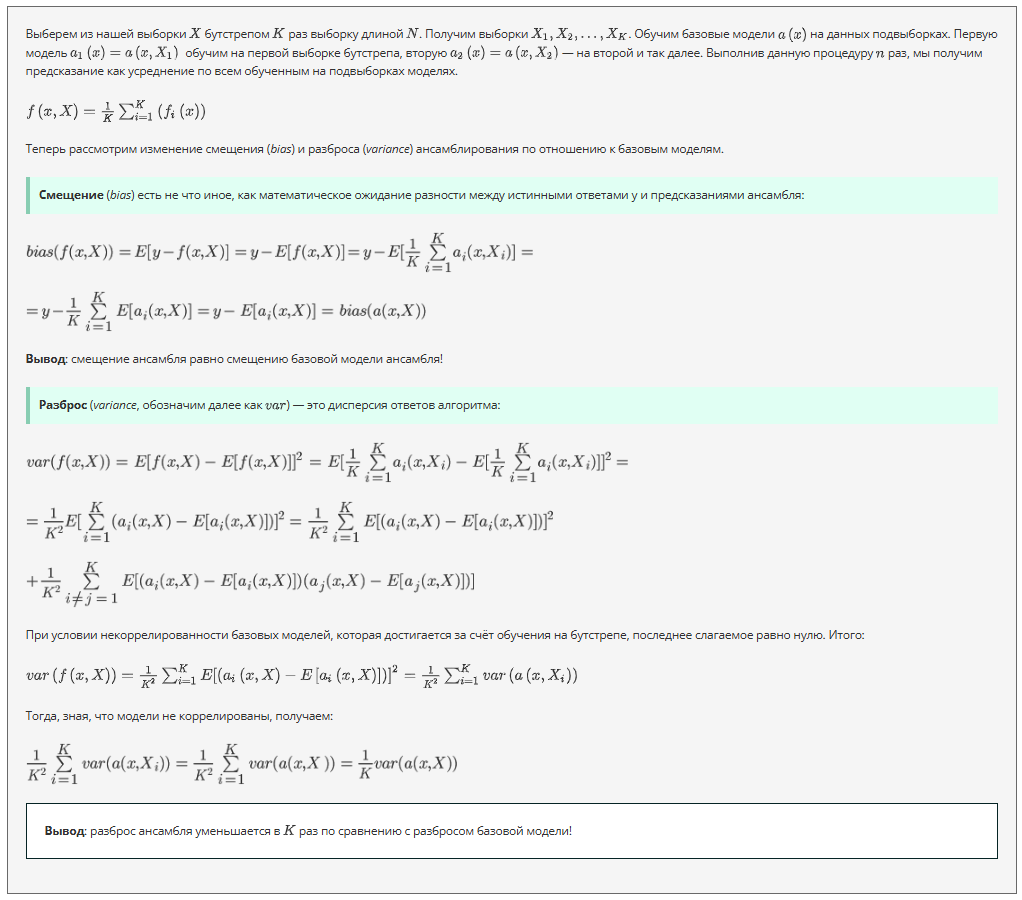

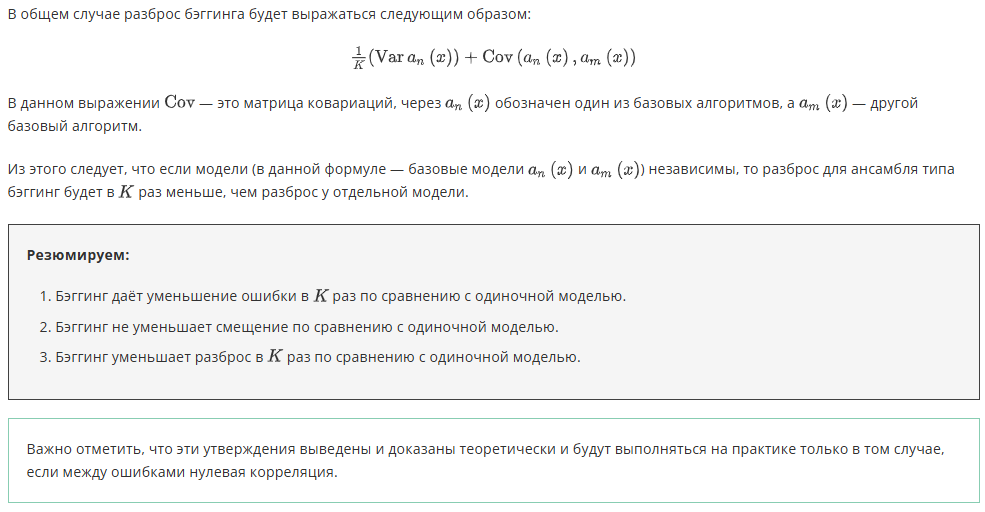

In [1]:
import pandas as pd
df = pd.read_csv('data/wineQualityReds.csv')
df = df.drop('Unnamed: 0',axis=1)
df

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [2]:
df['target']=df['quality'].apply(lambda x: 1 if x >=6 else 0)
df.sample(10)

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality,target
319,9.6,0.77,0.12,2.9,0.082,30.0,74.0,0.99865,3.30,0.64,10.4,6,1
581,12.3,0.50,0.49,2.2,0.089,5.0,14.0,1.00020,3.19,0.44,9.6,5,0
353,13.5,0.53,0.79,4.8,0.120,23.0,77.0,1.00180,3.18,0.77,13.0,5,0
897,7.1,0.59,0.01,2.3,0.080,27.0,43.0,0.99550,3.42,0.58,10.7,6,1
1219,9.0,0.39,0.40,1.3,0.044,25.0,50.0,0.99478,3.20,0.83,10.9,6,1
806,8.4,0.25,0.39,2.0,0.041,4.0,10.0,0.99386,3.27,0.71,12.5,7,1
232,8.5,0.37,0.20,2.8,0.090,18.0,58.0,0.99800,3.34,0.70,9.6,6,1
372,9.1,0.28,0.48,1.8,0.067,26.0,46.0,0.99670,3.32,1.04,10.6,6,1
1508,7.1,0.27,0.60,2.1,0.074,17.0,25.0,0.99814,3.38,0.72,10.6,6,1
321,9.3,0.61,0.26,3.4,0.090,25.0,87.0,0.99975,3.24,0.62,9.7,5,0


In [3]:
from sklearn.model_selection import train_test_split
X = df.drop(['target','quality'],axis = 1)
y = df['target']

In [4]:
y.value_counts(normalize=True)

target
1    0.534709
0    0.465291
Name: proportion, dtype: float64

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3,random_state=42,shuffle=True)

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
lg = LogisticRegression(random_state=42)
lg.fit(X_train,y_train)
y_pred = lg.predict(X_test)
print(f1_score(y_test, y_pred))

0.7542857142857143


c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [7]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=10,random_state=42)
dt.fit(X_train,y_train)
y_pred = dt.predict(X_test)
print(f1_score(y_test,y_pred))


0.7927927927927927


In [8]:
from sklearn.ensemble import BaggingClassifier
bc = BaggingClassifier(estimator=dt, n_estimators=1500)
bc.fit(X_train,y_train)
y_pred = bc.predict(X_test)
print(round(f1_score(y_test,y_pred),3))

0.82


---

# <center> **3. Случайный лес**

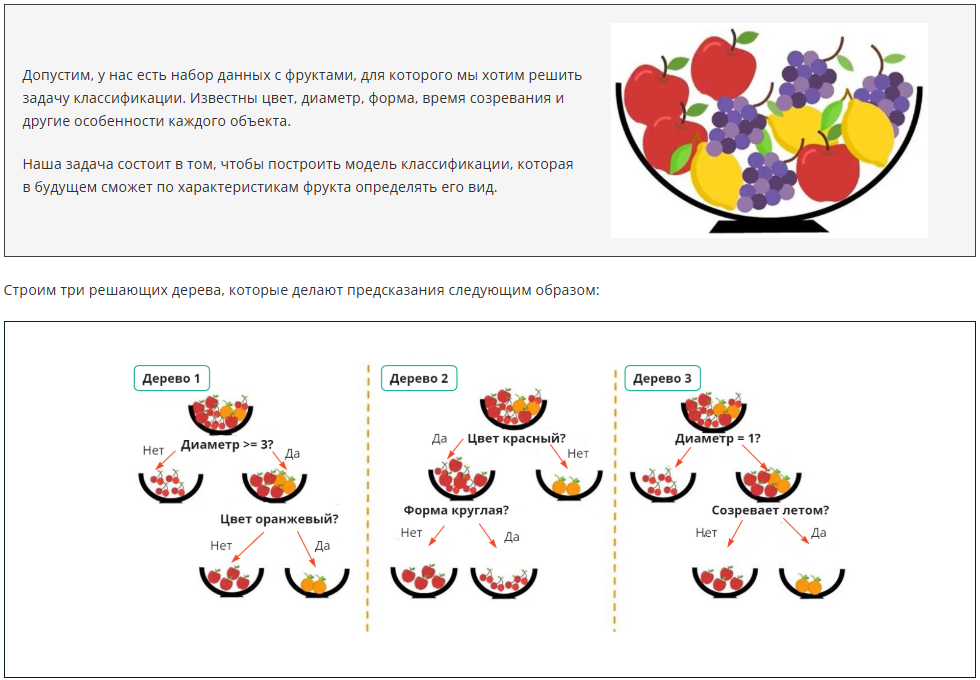

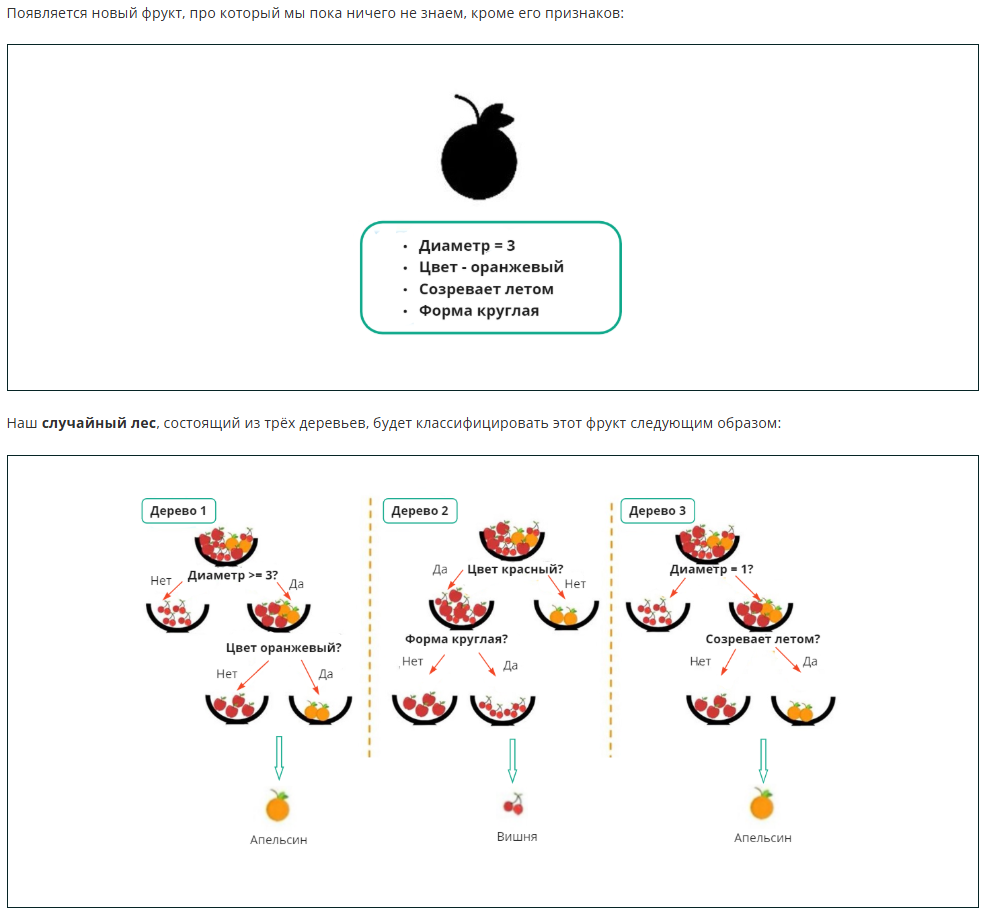

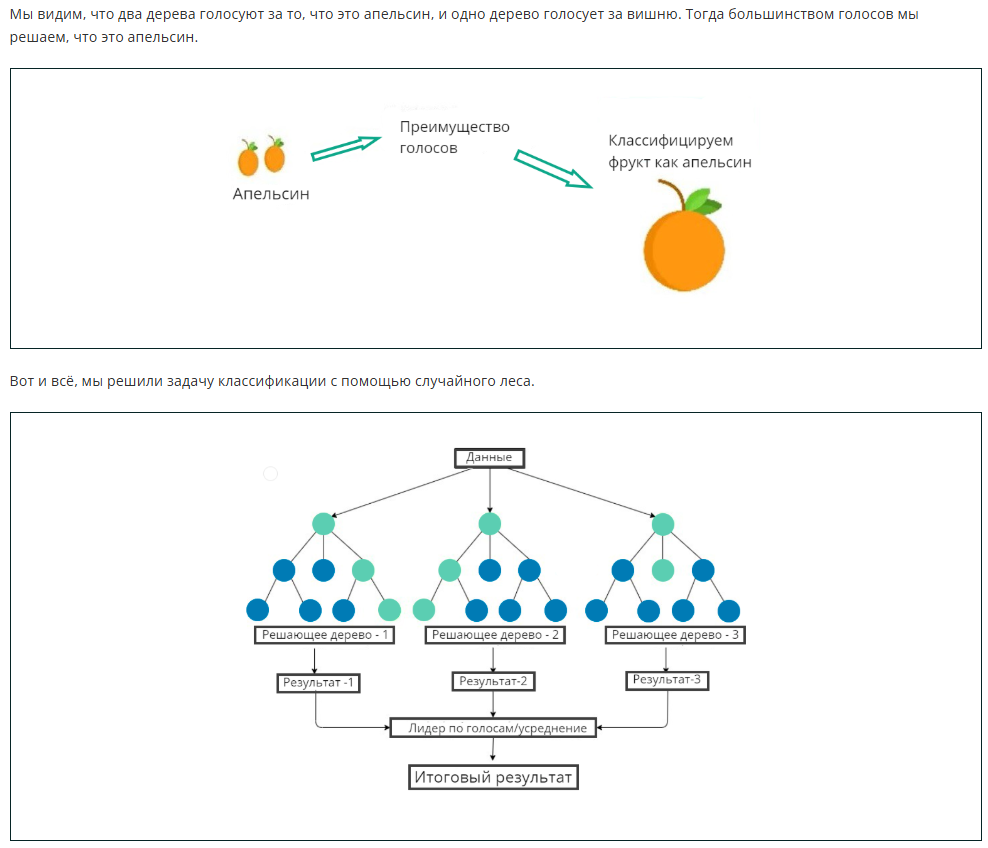

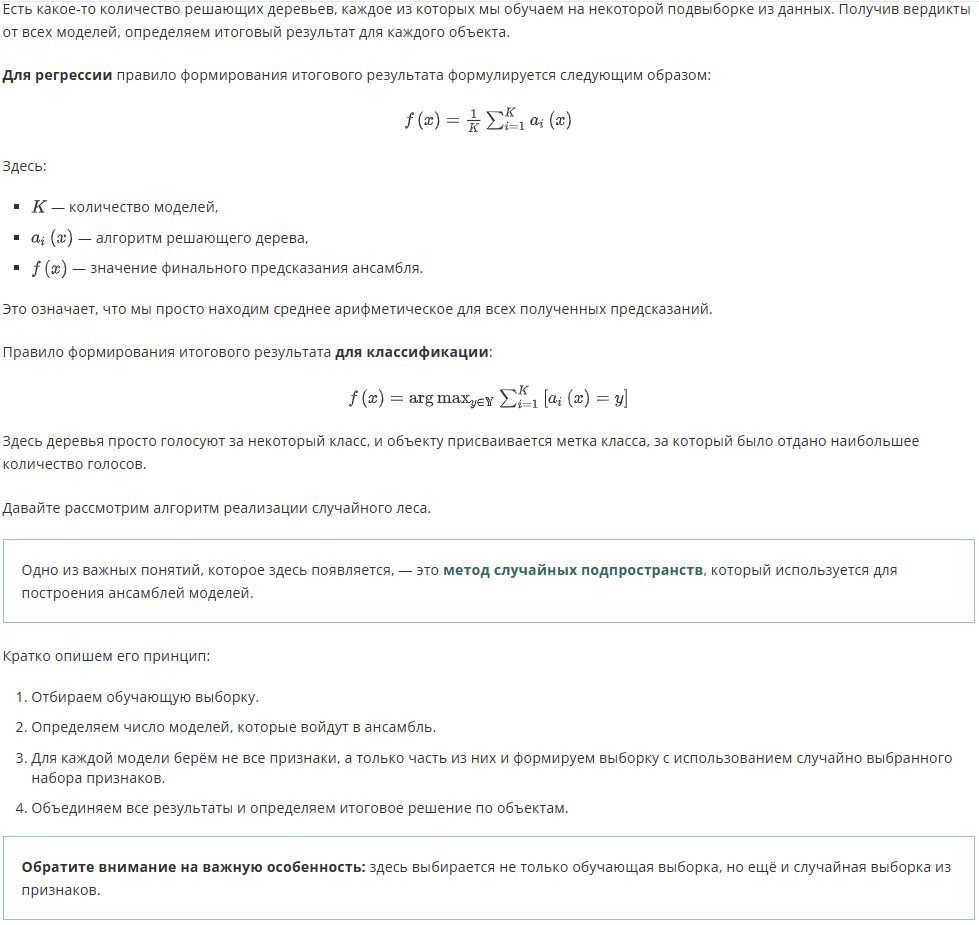

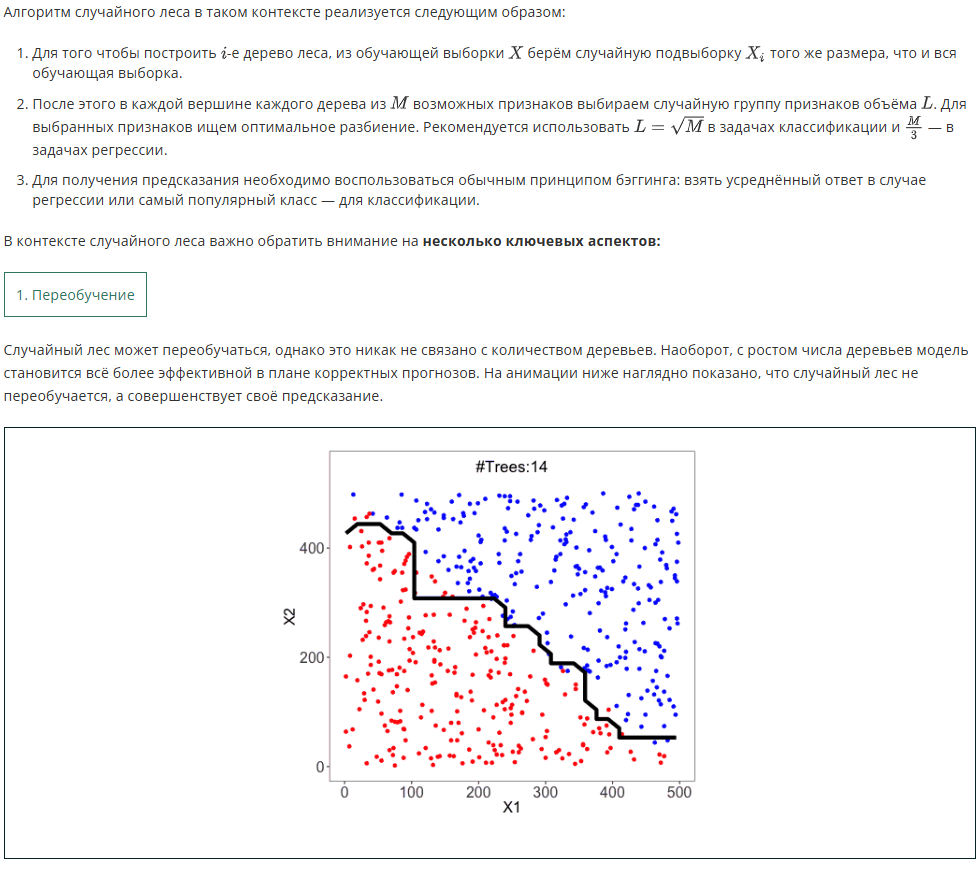

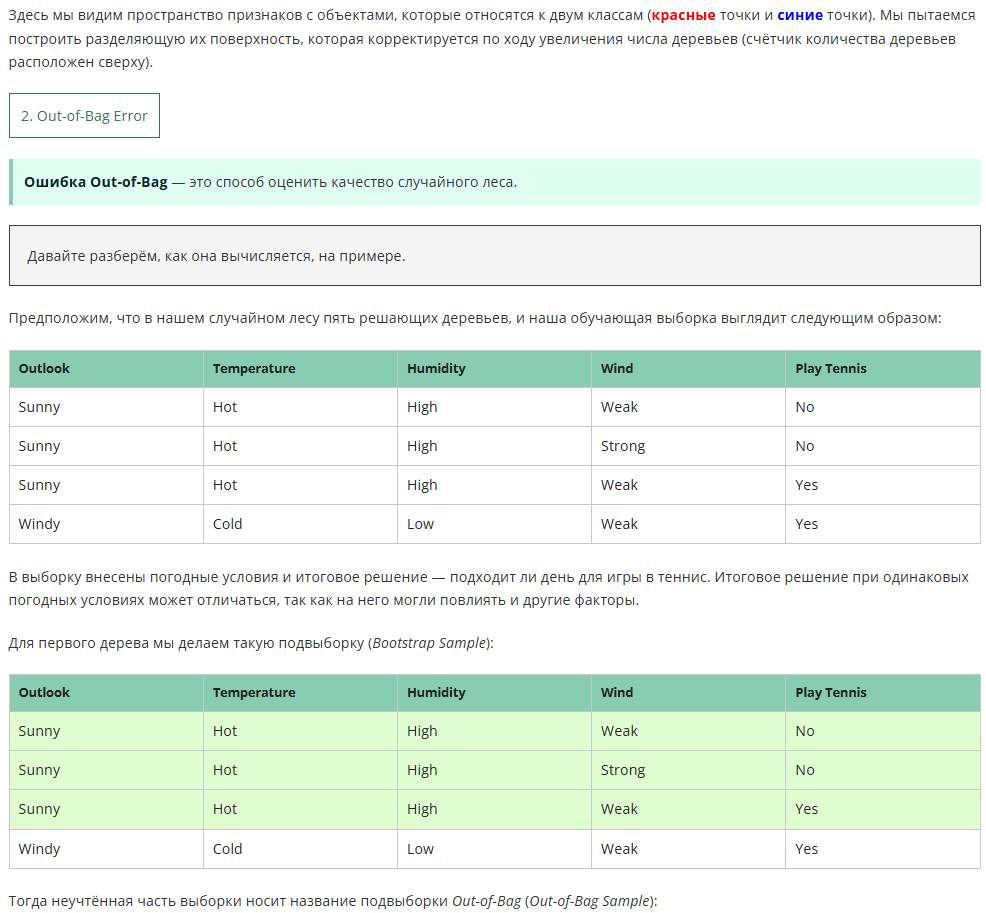

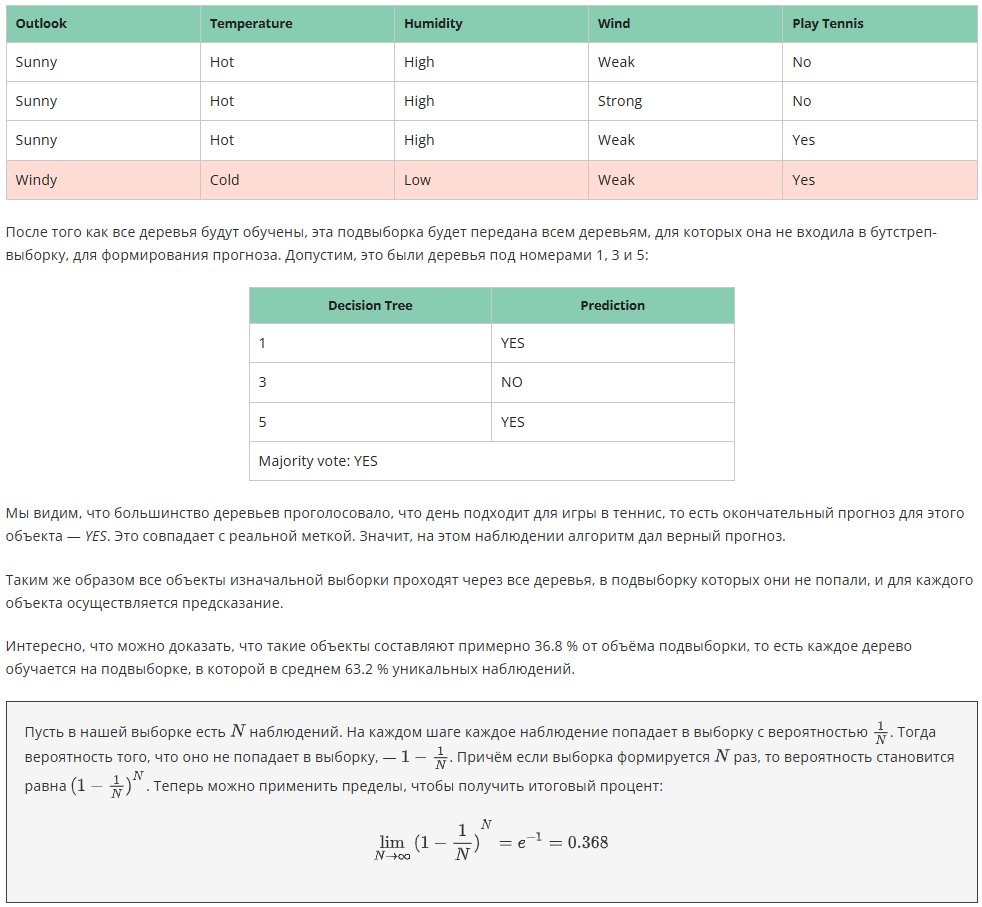

Примечание. Данный переход напрямую следует из второго замечательного предела. К сожалению, эта часть математического анализа выходит за пределы нашего курса, однако если вам интересно изучить её подробнее, рекомендуем ознакомиться с [этим материалом](https://mathprofi.ru/zamechatelnye_predely.html).

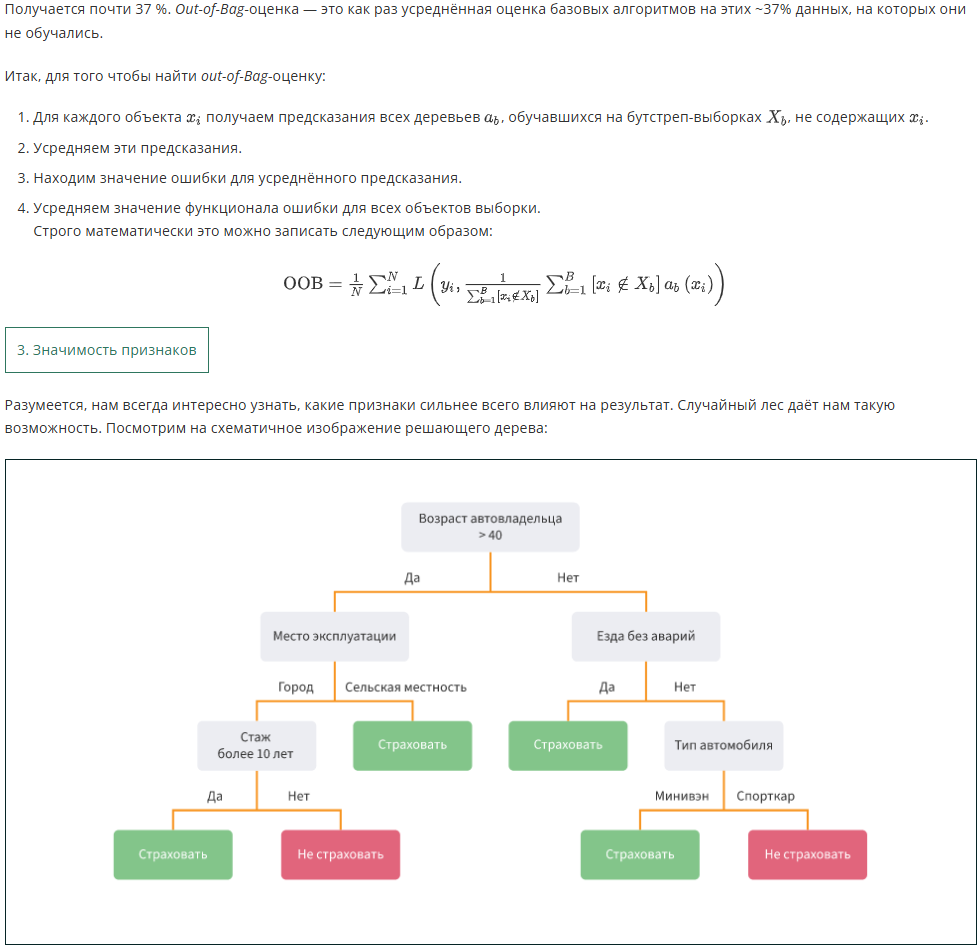

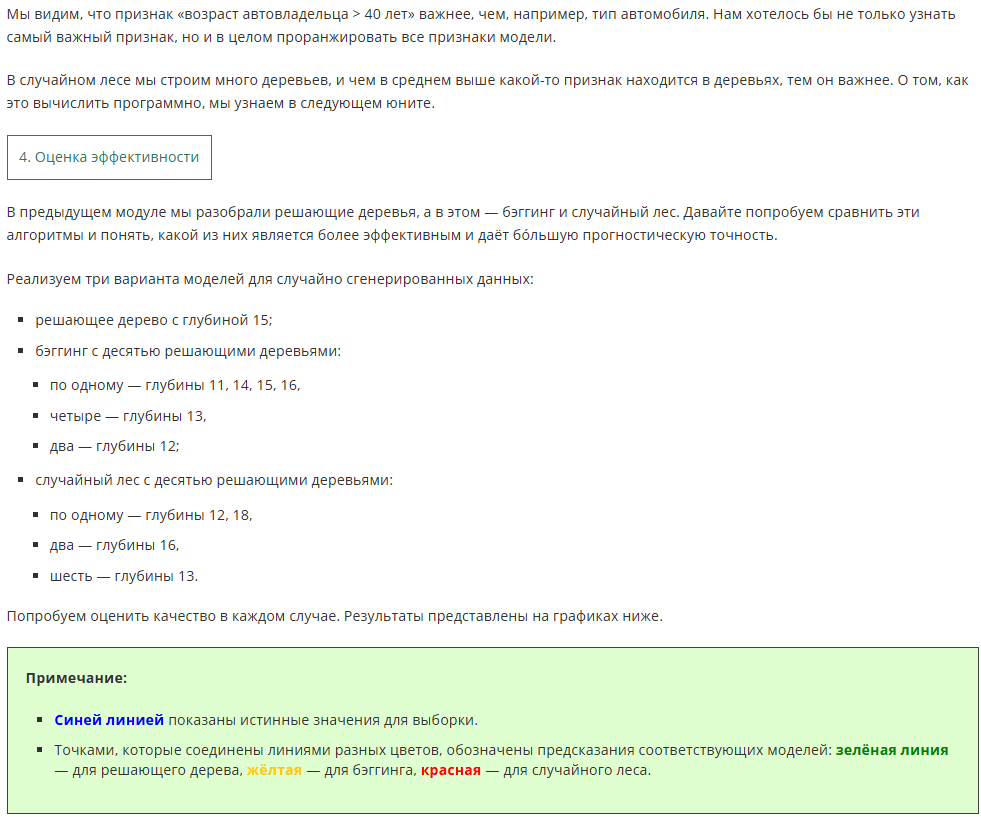

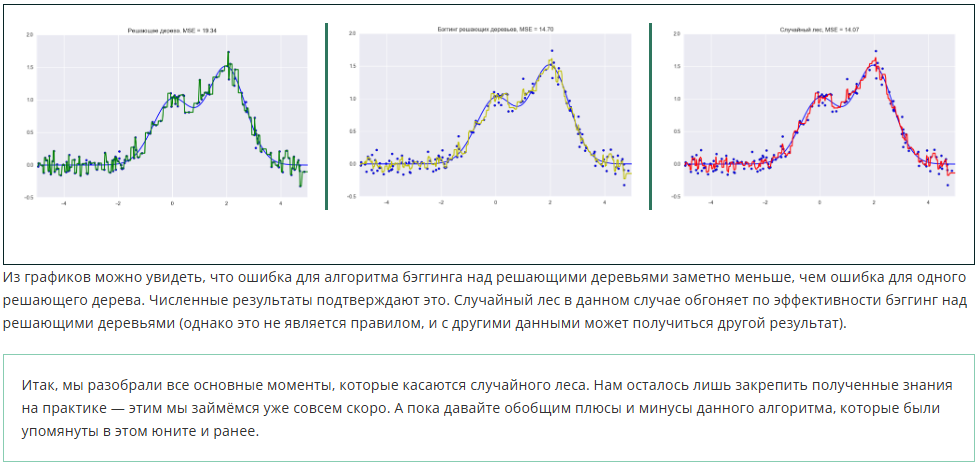

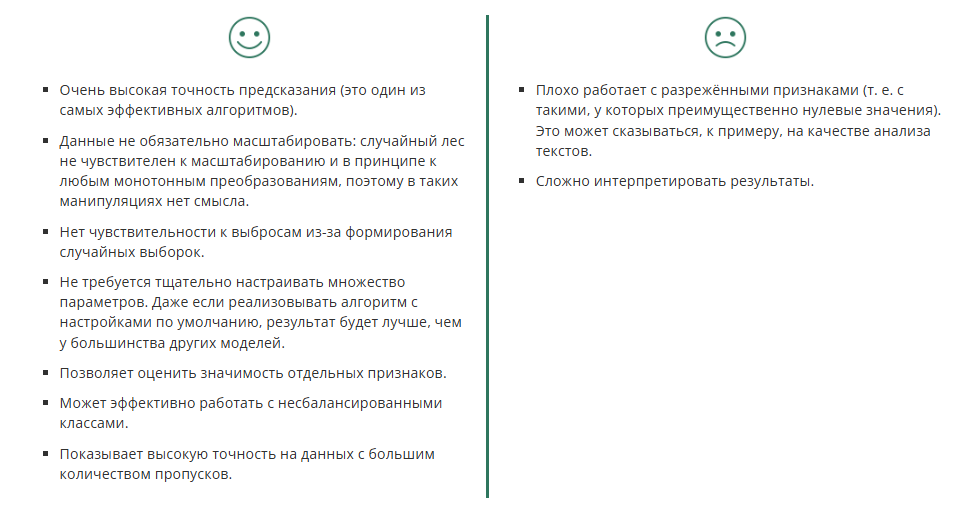

In [53]:
df = pd.read_csv('data/boston (1).csv',decimal=',')
df

,crim_rate,zn,business,river,nit_oxiden,rooms,age,dist,highways_index,tax,pup_per_teaс,lower,target
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0


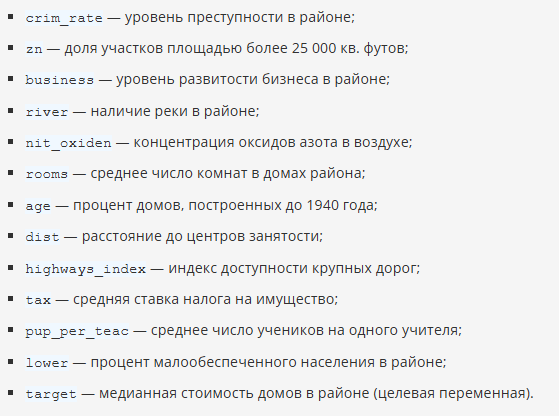

In [55]:
X = df.drop('target',axis = 1)
y = df['target']

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=13)

In [60]:
y_train.mean()

22.77316384180791

In [58]:
from sklearn.linear_model import LinearRegression
lr =LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

from sklearn.metrics import mean_absolute_error
print(mean_absolute_error(y_test,y_pred))

3.7222793958561513


In [59]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=13)
dt.fit(X_train,y_train)
y_pred = dt.predict(X_test)
print(mean_absolute_error(y_test,y_pred))

2.8388157894736845


In [61]:
from sklearn.ensemble import RandomForestRegressor
rf1 = RandomForestRegressor(n_estimators=3,random_state=13)
rf2 = RandomForestRegressor(n_estimators=10,random_state=13)
rf3 = RandomForestRegressor(n_estimators=100,random_state=13)
rf4 = RandomForestRegressor(n_estimators=500,random_state=13)
rf1.fit(X_train,y_train)
rf2.fit(X_train,y_train)
rf3.fit(X_train,y_train)
rf4.fit(X_train,y_train)
y_pred1 = rf1.predict(X_test)
y_pred2 = rf2.predict(X_test)
y_pred3 = rf3.predict(X_test)
y_pred4 = rf4.predict(X_test)
print(f"1 лес {mean_absolute_error(y_test,y_pred1)}")
print(f"2 лес {mean_absolute_error(y_test,y_pred2)}")
print(f"3 лес {mean_absolute_error(y_test,y_pred3)}")
print(f"4 лес {mean_absolute_error(y_test,y_pred4)}")

1 лес 2.9328947368421057
2 лес 2.466315789473684
3 лес 2.2559736842105265
4 лес 2.2365657894736892


---

## <center> 4. Случайный лес. Практика